# MATRIX Baseline — Canonical-Cycle Timing Diagrams

Reads the baseline `state_events` from `database/matrix.db`, segments the pooled
stream into individual workpiece cycles (one cycle = one rising edge of
`sliderMagazine`), aligns every cycle to its own start (t=0), and builds a
**canonical timing diagram** per stage.

**How averaging is done (and why it's honest).** The process is discrete, so each
signal is a digital waveform. We do NOT average raw timestamps (cycles start at
different wall-clock moments) and we do NOT fake "the Nth edge" for signals whose
edge count varies cycle-to-cycle. Instead, for every signal we compute the
**modal value at each time offset** across all cycles — the typical waveform — and
for *consistent* signals (same edge count in most cycles) we overlay each edge's
**mean ± std offset**. Variable signals are drawn but tagged `(variable)`, and
dead signals (never change) are excluded with a note.

The same machinery powers the attack notebook later: overlay the attacked
waveform on this baseline and shade the attack window.

Set `RUN_PREFIX` / `DB_PATH` below, then Run All.


In [19]:
# --- Configuration -------------------------------------------------------
import os

# Paths resolve to the REPO ROOT, so this notebook works whether run from the repo
# root OR from notebooks/ (where it lives). We walk up from the working directory
# until we find a database/ folder.
def _find_base():
    d = os.getcwd()
    for _ in range(6):
        if os.path.isdir(os.path.join(d, "database")):
            return d
        parent = os.path.dirname(d)
        if parent == d:
            break
        d = parent
    return os.getcwd()

BASE    = _find_base()                                  # repo root
DB_PATH = os.path.join(BASE, "database", "matrix.db")   # the logger's SQLite file
FIG_DIR = os.path.join(BASE, "results", "baseline-figures")
os.makedirs(FIG_DIR, exist_ok=True)
print("repo root:", BASE)
print("database :", DB_PATH, "(exists:", os.path.exists(DB_PATH), ")")
print("figures  :", FIG_DIR)

RUN_PREFIX = "baseline30wps"            # runs to pool: run_id LIKE '<prefix>_%'
CYCLE_SIGNAL   = "sliderMagazine"       # cycle starts on this signal's 0->1 edge
GRID_DT        = 0.05                   # s, timing-diagram resolution
MIN_CYCLE_S    = 6.0                    # drop implausibly short cycles
MIN_RUN_CYCLES = 10                     # skip aborted runs with fewer cycles
CONSISTENT_FRAC = 0.80                  # a signal is "consistent" if the modal
                                        # edge-count holds in >= this frac of cycles

# Which signals appear in each stage panel, and in what row order (top->bottom).
# The handshake code that bridges to the NEXT stage is included at the bottom of
# the stage that writes it, so the handoff is visible. Edit to taste; unknown or
# dead signals are skipped automatically.
STAGES = {
    "Turntable (Siemens S7-1200)": [
        "sliderMagazine", "magazineEmpty", "inPosition", "motorTurntable",
        "drillActive", "weldActive", "transferPart",
        "siemensHandshakeCode",                     # handoff Turntable -> Transfer
    ],
    "Transfer Unit (AB Micro820)": [
        "siemensHandshakeCode",                     # handoff in (from Turntable)
        "transferUnitAtTurntable", "rotateToTable", "vacuumGripper",
        "rotateToConveyor", "transferUnitAtConveyor", "transferUnitPositionCode",
        "schneiderHandshakeCode",                   # handoff out: AB -> TM221 "ready"
    ],
    "Conveyor (Schneider TM221)": [
        "schneiderHandshakeCode",                   # "ready" in (from AB)
        "workpieceOnConveyor", "conveyorBelt", "separatorValve",
        "sliderMotor", "palletReady", "workpieceOnPallet",
        "schneiderHandshakeACK",                    # "ack" back: TM221 -> AB
    ],
}
# Handshake / position codes are multi-level integers, drawn as stepped traces.
# NOTE: the AB<->TM221 handshake now uses TWO registers (TM221 ModbusIOScanner
# needs separate read/write regs): schneiderHandshakeCode = "ready" (AB->TM221),
# schneiderHandshakeACK = "ack" (TM221->AB). The old single arduinoHandshakeCode
# tag is gone.
INT_SIGNALS = {"siemensHandshakeCode", "schneiderHandshakeCode",
               "schneiderHandshakeACK", "transferUnitPositionCode", "workpiecesCount"}

import sqlite3, shutil, tempfile
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from collections import Counter

mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "font.family": "serif", "font.size": 9,
    "axes.titlesize": 10, "axes.labelsize": 9, "savefig.bbox": "tight",
})
COL_W, FULL_W = 3.5, 7.16

def savefig(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(FIG_DIR, f"{name}.{ext}"))
    print("saved:", name)

repo root: C:\Users\chabz\Matrix-ICS-Testbed
database : C:\Users\chabz\Matrix-ICS-Testbed\database\matrix.db (exists: True )
figures  : C:\Users\chabz\Matrix-ICS-Testbed\results\baseline-figures


In [20]:
# --- Load (read-only; copy if the DB sits on a read-only mount) ----------
def load_df(db_path, prefix):
    # Robust, cross-platform open (the previous file:...?mode=ro URI broke on
    # Windows paths like C:\...). Open normally in query-only mode; if the folder
    # is read-only (e.g. a mounted uploads dir), copy to temp and open that.
    q = ("SELECT run_id, ts_monotonic, tag, value, prev_value, vtype "
         "FROM state_events WHERE run_id LIKE ? ORDER BY run_id, seq")
    try:
        con = sqlite3.connect(db_path)
        con.execute("PRAGMA query_only=ON;")        # read-only, no writes
        df = pd.read_sql_query(q, con, params=(prefix + "_%",))
        con.close()
        return df
    except sqlite3.OperationalError:
        tmp = os.path.join(tempfile.gettempdir(), "matrix_ro_copy.db")
        shutil.copy(db_path, tmp)
        con = sqlite3.connect(tmp)
        df = pd.read_sql_query(q, con, params=(prefix + "_%",))
        con.close()
        return df

def coerce(v, vt):
    if vt == "bool":
        return 1.0 if str(v) == "True" else 0.0
    try:
        return float(v)
    except (TypeError, ValueError):
        return np.nan

df = load_df(DB_PATH, RUN_PREFIX)
df["num"]  = [coerce(v, vt) for v, vt in zip(df["value"], df["vtype"])]
df["pnum"] = [coerce(v, vt) for v, vt in zip(df["prev_value"], df["vtype"])]
print(f"loaded {len(df):,} rows across {df.run_id.nunique()} runs")
print("tags:", df.tag.nunique())

loaded 7,470 rows across 5 runs
tags: 36


In [21]:
# --- Segment into cycles on CYCLE_SIGNAL rising edges --------------------
# A cycle is [t0, t1) between consecutive rising edges, per run. We keep cycles
# of plausible length and skip aborted runs. Each surviving cycle is pooled.
# A cycle is [rise_i, rise_{i+1}) between CONSECUTIVE rising edges (so the last,
# trailing partial segment of each run is naturally dropped -- it has no valid
# end). Aborted/short runs are skipped. We then drop implausibly short or long
# cycles (operator pauses) so the canonical takt is built from clean cycles only.
raw = []     # (run_id, t0, t1) for every consecutive-rise segment
per_run = {}
for rid, g in df.groupby("run_id"):
    sm = g[g.tag == CYCLE_SIGNAL]
    rises = sm[sm.num == 1.0]["ts_monotonic"].tolist()
    per_run[rid] = len(rises)
    if len(rises) < MIN_RUN_CYCLES:
        continue
    for i in range(len(rises) - 1):      # consecutive rises only -> no trailing partial
        raw.append((rid, rises[i], rises[i + 1]))

med = float(np.median([t1 - t0 for _, t0, t1 in raw]))   # robust takt length
MAX_CYCLE_S = 2.0 * med                                   # drop paused/outlier takts
cycles = [(r, a, b) for (r, a, b) in raw if MIN_CYCLE_S <= (b - a) <= MAX_CYCLE_S]

print("Per-run rising edges (runs with < %d excluded):" % MIN_RUN_CYCLES)
for rid, n in sorted(per_run.items()):
    flag = "" if n >= MIN_RUN_CYCLES else "   <-- aborted/short, EXCLUDED"
    print(f"  {rid:<24} {n:>3} edges{flag}")
durs = np.array([t1 - t0 for _, t0, t1 in cycles])
WINDOW = float(np.median(durs))
print(f"\nCandidate segments: {len(raw)}  ->  clean cycles kept: {len(cycles)} "
      f"(dropped {len(raw)-len(cycles)} short/paused)")
print(f"Cycle (takt) duration: mean={durs.mean():.2f}s  median={np.median(durs):.2f}s "
      f"std={durs.std():.2f}s   window={WINDOW:.2f}s")

Per-run rising edges (runs with < 10 excluded):
  baseline30wps_0001        30 edges
  baseline30wps_0002        30 edges
  baseline30wps_0003        30 edges
  baseline30wps_0004        30 edges
  baseline30wps_0005        30 edges

Candidate segments: 145  ->  clean cycles kept: 145 (dropped 0 short/paused)
Cycle (takt) duration: mean=10.46s  median=10.60s std=0.86s   window=10.60s


In [22]:
# --- Per-(run,signal) step function, to sample any signal at any time ----
# Build sorted transition times + values per run+tag, seeded with the value at
# run start (prev_value of the first transition) so we know the level at t0.
step = {}   # (run_id, tag) -> (times ndarray, vals ndarray)
for (rid, tag), g in df.groupby(["run_id", "tag"]):
    g = g.sort_values("ts_monotonic")
    t = g["ts_monotonic"].to_numpy()
    v = g["num"].to_numpy()
    seed_t = df[df.run_id == rid]["ts_monotonic"].min() - 1.0
    seed_v = g["pnum"].iloc[0]
    if np.isnan(seed_v):
        seed_v = v[0]
    step[(rid, tag)] = (np.concatenate([[seed_t], t]),
                        np.concatenate([[seed_v], v]))

def sample(rid, tag, qt):
    """Value(s) of (rid,tag) at query time(s) qt (step-hold). NaN if no series."""
    key = (rid, tag)
    if key not in step:
        return np.full(np.shape(qt), np.nan)
    tt, vv = step[key]
    idx = np.searchsorted(tt, qt, side="right") - 1
    idx = np.clip(idx, 0, len(vv) - 1)
    return vv[idx]

# Common grid for the canonical cycle.
GRID = np.arange(0.0, WINDOW + GRID_DT, GRID_DT)
NG = len(GRID)

# Resample every cycle of every tag onto the grid -> matrix [n_cycles x NG].
# Points past a cycle's own end are NaN (so averages use only cycles with data).
ALL_TAGS = sorted(df.tag.unique())
occ = {}    # tag -> matrix
for tag in ALL_TAGS:
    M = np.full((len(cycles), NG), np.nan)
    for ci, (rid, t0, t1) in enumerate(cycles):
        qt = t0 + GRID
        vals = sample(rid, tag, qt)
        vals = np.where(qt < t1, vals, np.nan)   # mask beyond this cycle
        M[ci] = vals
    occ[tag] = M
coverage = np.mean(~np.isnan(occ[ALL_TAGS[0]]), axis=0)   # frac cycles w/ data vs t
print(f"resampled {len(ALL_TAGS)} signals onto {NG}-point grid "
      f"({GRID_DT}s) over {WINDOW:.1f}s")

resampled 36 signals onto 213-point grid (0.05s) over 10.6s


In [23]:
# --- Per-signal consistency + edge statistics ----------------------------
# edge count per cycle (transitions within [t0,t1)); modal count and its fraction.
def edge_counts(tag):
    cnt = []
    for (rid, t0, t1) in cycles:
        tt, vv = step[(rid, tag)]
        m = (tt >= t0) & (tt < t1)
        cnt.append(int(m.sum()))
    return cnt

report = []
for tag in ALL_TAGS:
    cnts = edge_counts(tag)
    c = Counter(cnts); mode, mc = c.most_common(1)[0]
    frac = mc / len(cnts)
    dead = (set(cnts) == {0})
    kind = "dead" if dead else ("consistent" if frac >= CONSISTENT_FRAC else "variable")
    report.append({"tag": tag, "kind": kind, "modal_edges": mode,
                   "modal_frac": round(frac, 2)})
report = pd.DataFrame(report).set_index("tag")
print("Signal classification:")
display(report)

# Baseline timing of CONSISTENT boolean signals, reported as two SEPARATE,
# physically-meaningful quantities (the line is PIPELINED, so a signal's pulse can
# straddle the takt boundary -- "fall minus rise" within a window is NOT the pulse
# width and can go negative). Instead:
#   rise_phase = time from takt start (t0) to the signal's rising edge  -> WHEN in
#                the takt it fires (0..window).
#   pulse_width = rise -> the NEXT falling edge in the full run stream   -> HOW LONG
#                it stays on (correct even when the pulse crosses the takt boundary).
def rising_edges(tt, vv):
    return np.where((vv == 1) & (np.concatenate([[0], vv[:-1]]) != 1))[0]

edge_stats = []
for tag in ALL_TAGS:
    if report.loc[tag, "kind"] != "consistent" or tag in INT_SIGNALS:
        continue
    phases, widths = [], []
    for (rid, t0, t1) in cycles:
        tt, vv = step[(rid, tag)]
        for j in rising_edges(tt, vv):
            if t0 <= tt[j] < t1:                       # a rise belonging to this takt
                phases.append(tt[j] - t0)
                later = np.where((tt > tt[j]) & (vv == 0))[0]  # next fall in the run
                if later.size:
                    widths.append(tt[later[0]] - tt[j])
    # Keep only PER-TAKT signals (fire in >= half the cycles). This drops
    # run-lifetime signals like siemensStartCommand / heartbeats (which fire once
    # per RUN, giving meaningless ~300 s "pulse widths") and rare events.
    if phases and len(phases) >= 0.5 * len(cycles):
        edge_stats.append({"signal": tag,
            "rise_phase_mean_s": round(np.mean(phases), 3),
            "rise_phase_std_s":  round(np.std(phases), 3),
            "pulse_width_mean_s": round(np.mean(widths), 3) if widths else np.nan,
            "pulse_width_std_s":  round(np.std(widths), 3) if widths else np.nan,
            "n": len(phases)})
edge_stats = pd.DataFrame(edge_stats)
if len(edge_stats):
    edge_stats = edge_stats.sort_values("rise_phase_mean_s")
else:
    # keep expected columns so downstream code (plot markers) never KeyErrors
    edge_stats = pd.DataFrame(columns=["signal", "rise_phase_mean_s",
        "rise_phase_std_s", "pulse_width_mean_s", "pulse_width_std_s", "n"])
print("\nBaseline signal timing (consistent on/off signals):")
print("  rise_phase = when in the takt it fires;  pulse_width = how long it's on")
display(edge_stats)
edge_stats.to_csv(os.path.join(FIG_DIR, "baseline_edge_timing.csv"), index=False)
try:
    with open(os.path.join(FIG_DIR, "baseline_edge_timing.tex"), "w") as f:
        f.write(edge_stats.to_latex(index=False))
except Exception:
    pass
print("saved: baseline_edge_timing.csv/.tex")

Signal classification:


,kind,modal_edges,modal_frac
tag,,,
ab_connected,dead,0,1.00
controllerActive,consistent,0,0.97
controllerActiveIndicator,variable,2,0.59
conveyorBelt,consistent,2,0.88
drillActive,consistent,2,0.97
drillPart,consistent,2,0.95
inPosition,consistent,2,1.00
magazineEmpty,variable,0,0.66
magazinePart,consistent,2,1.00



Baseline signal timing (consistent on/off signals):
  rise_phase = when in the takt it fires;  pulse_width = how long it's on


,signal,rise_phase_mean_s,rise_phase_std_s,pulse_width_mean_s,pulse_width_std_s,n
8,sliderMagazine,0.000,0.000,1.992,0.231,145
2,drillPart,0.092,0.872,2.989,0.267,140
6,rotateToConveyor,1.443,0.510,1.345,0.366,130
4,magazinePart,1.978,0.259,8.480,0.827,145
11,transferUnitAtConveyor,2.769,0.479,1.181,0.316,130
0,conveyorBelt,4.692,0.570,2.513,0.257,130
9,tm221ActiveIndicator,4.693,0.570,2.834,0.575,130
7,separatorValve,4.695,0.568,2.514,0.257,130
5,motorTurntable,4.808,0.725,5.642,0.514,145
13,workpieceOnConveyor,4.944,0.687,8.141,1.548,136


saved: baseline_edge_timing.csv/.tex


## Timing diagrams

One lane per signal; the trace is the **modal value** across cycles (the typical
waveform). Boolean signals are 0/1; handshake / position codes are multi-level
(0/1/2...) and drawn to scale in their lane. For *consistent* on/off signals the
mean rising/falling edges are marked with a `|` and a horizontal error bar
(±1 std). Variable signals are drawn lighter and tagged. Dead signals are skipped.


saved: timing_stage1


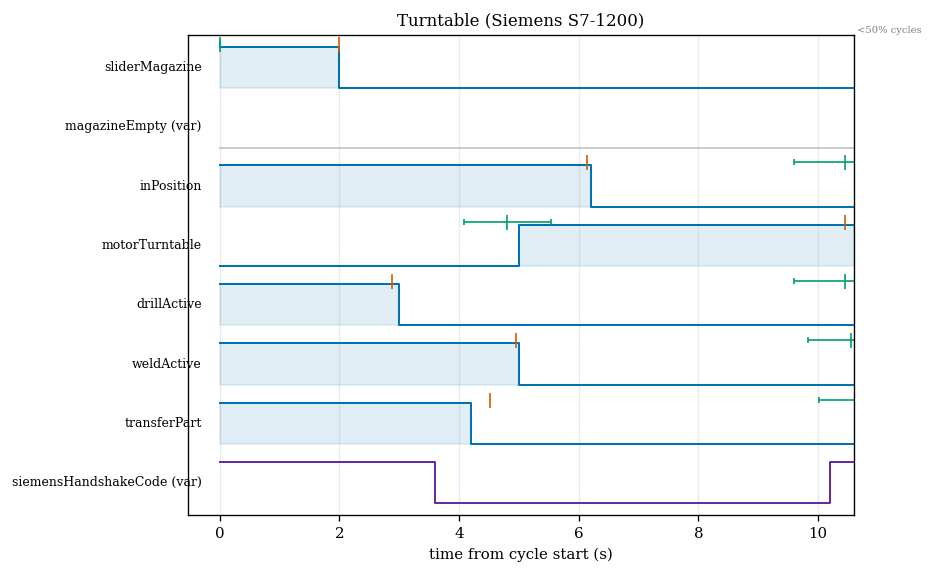

saved: timing_stage2


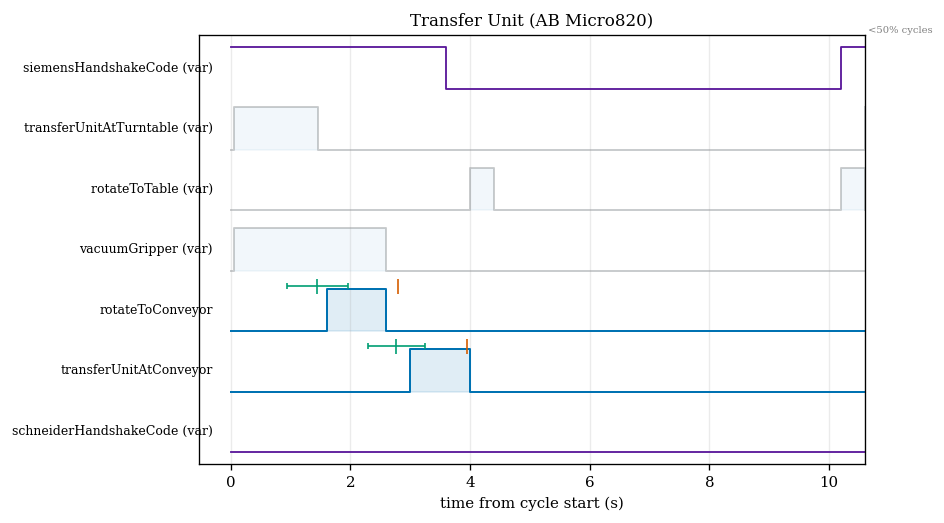

saved: timing_stage3


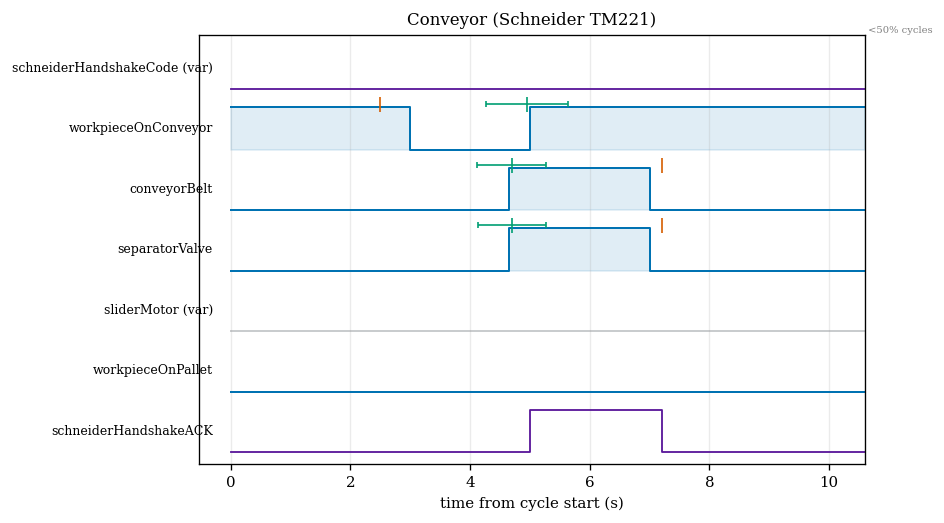

In [24]:
def modal_trace(tag):
    """Modal (most-common) value at each grid point across cycles -> crisp trace."""
    M = occ[tag]
    out = np.full(NG, np.nan)
    for j in range(NG):
        col = M[:, j]; col = col[~np.isnan(col)]
        if col.size:
            vals, counts = np.unique(col, return_counts=True)
            out[j] = vals[np.argmax(counts)]
    return out

def draw_stage(title, signals, fname):
    # keep only known, non-dead signals present in the data
    rows = [s for s in signals if s in ALL_TAGS and report.loc[s, "kind"] != "dead"]
    if not rows:
        print(f"[{title}] no drawable signals"); return
    fig, ax = plt.subplots(figsize=(FULL_W, 0.55 * len(rows) + 0.8))
    for k, tag in enumerate(rows):
        y0 = len(rows) - 1 - k                 # top-to-bottom
        trace = modal_trace(tag)
        kind = report.loc[tag, "kind"]
        if tag in INT_SIGNALS:                 # multi-level code, scaled to lane
            mx = np.nanmax(trace) if np.nanmax(trace) > 0 else 1
            y = y0 + 0.1 + 0.7 * (trace / mx)
            ax.step(GRID, y, where="post", lw=1.1, color="#5A189A")
        else:                                  # boolean 0/1
            y = y0 + 0.1 + 0.7 * trace
            alpha = 1.0 if kind == "consistent" else 0.45
            ax.step(GRID, y, where="post", lw=1.2,
                    color="#0072B2" if kind == "consistent" else "#999999", alpha=alpha)
            ax.fill_between(GRID, y0 + 0.1, y, step="post",
                            color="#0072B2", alpha=0.12 if kind == "consistent" else 0.05)
            # mean rising edge (green) +/-std, and the matched falling edge
            # (orange) at rise_phase + pulse_width, wrapped into the window.
            es = edge_stats[edge_stats.signal == tag]
            if len(es):
                r = es.iloc[0]
                ax.errorbar(r.rise_phase_mean_s, y0 + 0.85, xerr=r.rise_phase_std_s,
                            fmt="|", color="#009E73", ms=9, capsize=2, lw=1)
                if not np.isnan(r.pulse_width_mean_s):
                    f = (r.rise_phase_mean_s + r.pulse_width_mean_s) % WINDOW
                    ax.plot([f], [y0 + 0.85], "|", color="#D55E00", ms=9)
        label = tag + (" (var)" if kind == "variable" else "")
        ax.text(-0.3, y0 + 0.45, label, ha="right", va="center", fontsize=7.5)
    # coverage fade: shade where fewer than half the cycles still have data
    half = GRID[coverage < 0.5]
    if half.size:
        ax.axvspan(half.min(), GRID[-1], color="grey", alpha=0.06)
        ax.text(half.min(), len(rows), " <50% cycles", fontsize=6, color="grey", va="bottom")
    ax.set_xlim(-0.05 * WINDOW, WINDOW); ax.set_ylim(-0.1, len(rows))
    ax.set_yticks([]); ax.set_xlabel("time from cycle start (s)")
    ax.set_title(title); ax.grid(axis="x", alpha=0.25)
    savefig(fig, fname); plt.show()

for i, (title, sigs) in enumerate(STAGES.items(), 1):
    draw_stage(title, sigs, f"timing_stage{i}")

saved: timing_overview


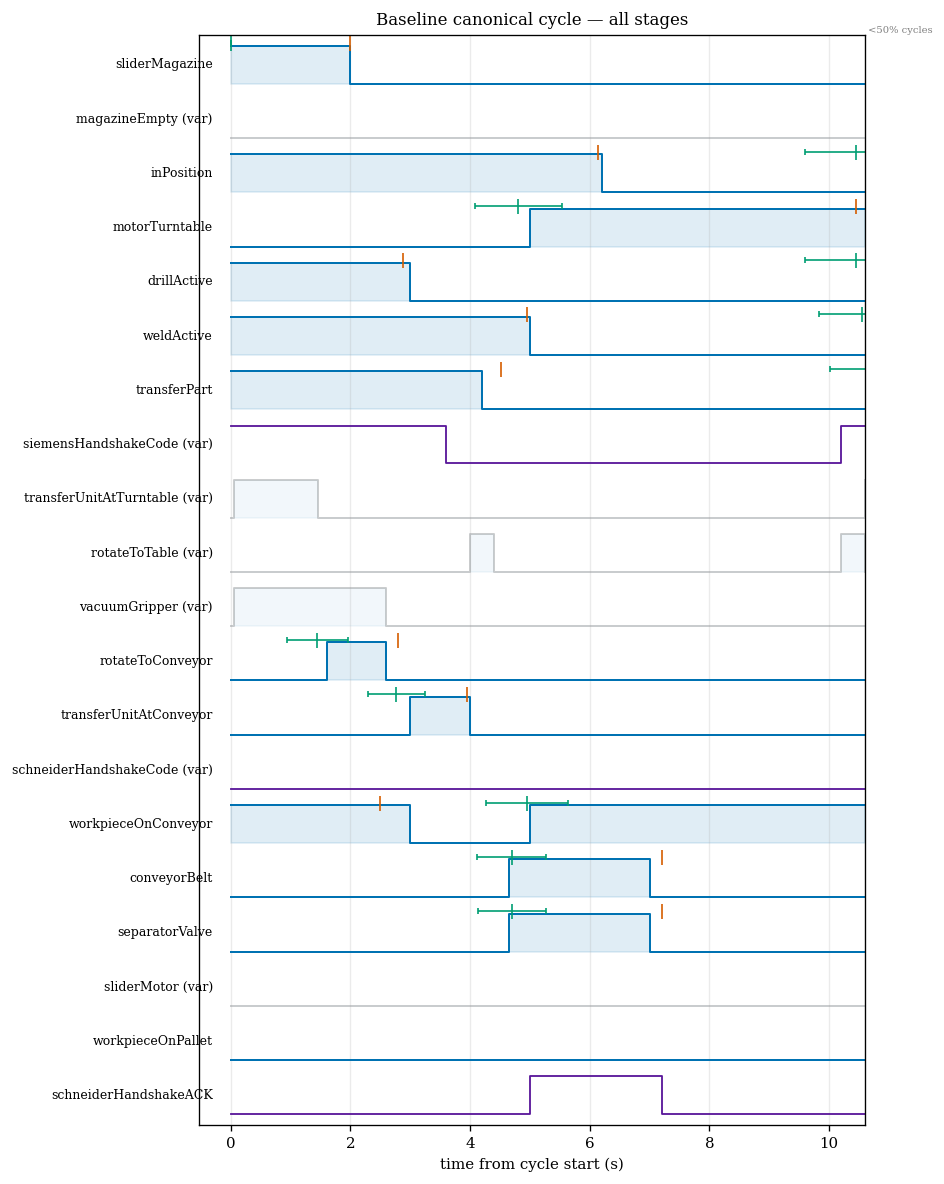

In [25]:
# --- Combined overview: every stage stacked, in process order -----------
overview = []
for sigs in STAGES.values():
    for s in sigs:
        if s in ALL_TAGS and s not in overview and report.loc[s, "kind"] != "dead":
            overview.append(s)
draw_stage("Baseline canonical cycle — all stages", overview, "timing_overview")

## Outputs

Figures and tables are in `results/baseline-figures/`:
`timing_stage1..3.pdf/png`, `timing_overview.pdf/png`,
`baseline_edge_timing.csv/.tex` (mean±std edge offsets — the quantitative baseline
that attacks are later measured against).

Reading note: *consistent* signals (solid blue, with green/orange edge markers)
have a well-defined on/off time; *variable* signals (grey, lighter) fire a
different number of times across cycles and are shown as their typical trace, not
a false average. Dead signals are omitted (e.g. the Schneider/reg2 handshake if
it isn't being captured under its tag — worth fixing in the server mapping so the
AB↔TM221 handoff shows up).
